# ЛР 3. Решающее дерево

## Данные

Avila. По 10 признакам фрагмента текста предсказываем одного из 12 переписчиков. Это помогает распределять фрагменты перед ручной проверкой. Используем разбиение UCI и три стратифицированных фолда в обучающей части. [Источник](https://doi.org/10.24432/C5K02X)

Tasmania. По координатам 16 преобразователей предсказываем мощность фермы. Это позволяет отбирать конфигурации перед запуском симулятора. Мощности отдельных преобразователей исключаем, поскольку их сумма практически равна цели. Берем 7200 конфигураций. Раскладки с одинаковыми координатами после округления до 10 м попадают в одну группу. Группы разделяем между обучением и тестом. В обучающей части три групповых фолда. [Источник](https://doi.org/10.24432/C5831S)

In [1]:
import pandas as pd
from IPython.display import display
from labkit.data import load_tasks
from labkit.experiments import (
    comparison_text, describe_data, evaluate_holdout, plot_predictions,
    plot_training, primary_metric, save_scores, select_candidates,
)

LAB = 3
tasks = load_tasks()
display(describe_data(tasks))
for task in tasks:
    display(pd.Series(task.audit, name=task.title).to_frame())

,задача,строк в исходных файлах,train,test,исходные признаки,разбиение
0,Avila,20867,10430,10437,10,"Разбиение UCI, 3 стратифицированных фолда на t..."
1,Tasmania,72000,5762,1438,32,"20% групп на тесте, 3 групповых фолда на train."


,Avila
Точных совпадений векторов признаков между train/test,0


,Tasmania
Строк после проверки диапазонов и пропусков,72000
Точных уникальных конфигураций,72000
Строк в воспроизводимой подвыборке,7200
Групп в подвыборке (округление координат до 10 м),7183


## Метрики

Avila. Macro-F1 дает одинаковый вес каждому классу. Balanced accuracy усредняет полноту по классам. Accuracy показывает общую долю верных ответов.

Tasmania. MAE показывает средний промах в МВт. RMSE сильнее учитывает крупные ошибки. R² сравнивает модель с прогнозом среднего.

Для сравнения простая модель предсказывает самый частый класс или медианную мощность из обучающей выборки.

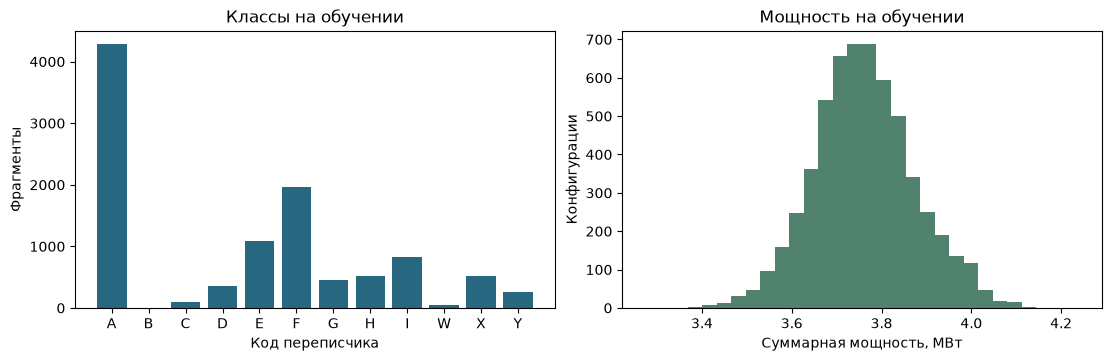

In [2]:
plot_training(tasks)

## Бейзлайн sklearn

Дерево sklearn использует Gini для классификации и квадратичную ошибку для регрессии. Глубина без ограничения. Минимум один объект в листе.

## Подбор параметров

Проверяем, снижают ли ограничение глубины и увеличение минимального размера листа переобучение. Для Avila также проверяем веса классов, для Tasmania сравниваем координаты и геометрические признаки.

Выбор по среднему macro-F1 или MAE на трех фолдах. Масштабирование обучается внутри каждого фолда. При равенстве оценок берем первый вариант.

In [3]:
selections = select_candidates(LAB, tasks)
for task in tasks:
    print(f"{task.title} ({primary_metric(task)})")
    display(selections[task.key][2].round(5))

Avila (macro_f1)


,гипотеза,признаки,настройки,CV среднее,CV std,фолд 1,фолд 2,фолд 3,выбран
0,Бейзлайн,raw,{},0.90412,0.01923,0.88252,0.91941,0.91042,False
1,Глубина 12 и минимум 3 в листе,raw,"{""max_depth"": 12, ""min_samples_leaf"": 3}",0.79098,0.06741,0.74606,0.75839,0.86850,False
2,Только веса классов,raw,"{""class_weight"": ""balanced""}",0.92155,0.05135,0.87383,0.91493,0.97589,True
3,Веса классов и ограничения дерева,raw,"{""max_depth"": 12, ""min_samples_leaf"": 3, ""clas...",0.74201,0.04604,0.69044,0.77898,0.75660,False
4,Минимум 2 в листе,raw,"{""min_samples_leaf"": 2}",0.87593,0.01775,0.85881,0.87472,0.89426,False


Tasmania (mae_mw)


,гипотеза,признаки,настройки,CV среднее,CV std,фолд 1,фолд 2,фолд 3,выбран
0,Бейзлайн,raw,{},0.07779,0.00100,0.07728,0.07895,0.07715,False
1,Глубина 12 и минимум 3 в листе,raw,"{""max_depth"": 12, ""min_samples_leaf"": 3}",0.07114,0.00091,0.07100,0.07031,0.07211,False
2,Геометрия,geometry,{},0.06895,0.00262,0.06597,0.07093,0.06993,False
3,Геометрия и ограничения дерева,geometry,"{""max_depth"": 12, ""min_samples_leaf"": 3}",0.06340,0.00236,0.06069,0.06502,0.06449,True


## Результаты sklearn

Начальную и выбранную модели обучаем на всей обучающей выборке и проверяем на тесте.

In [4]:
results = evaluate_holdout(LAB, tasks, selections)
for task in tasks:
    table, _ = results[task.key]
    base = table.loc[table["version"].isin(["dummy", "sklearn baseline", "sklearn tuned"])]
    print(task.title)
    display(base.dropna(axis=1, how="all").drop(columns=["lab", "task", "algorithm"]).round(5))

Avila


,version,candidate,fit_s,predict_s,macro_f1,balanced_accuracy,accuracy
0,dummy,Мода,NaN,NaN,0.04852,0.08333,0.41065
1,sklearn baseline,Бейзлайн,0.18959,0.00826,0.95820,0.96451,0.96924
2,sklearn tuned,Только веса классов,0.25357,0.00882,0.98517,0.98362,0.98726


Tasmania


,version,candidate,fit_s,predict_s,mae_mw,rmse_mw,r2
0,dummy,Медиана,NaN,NaN,0.08752,0.11228,-0.00000
1,sklearn baseline,Бейзлайн,0.59507,0.00483,0.07690,0.10132,0.18567
2,sklearn tuned,Геометрия и ограничения дерева,0.65856,0.10951,0.06159,0.08233,0.46229


## Своя реализация

CART перебирает пороги между соседними различными значениями признака. Выбирает разрез с минимальным взвешенным Gini или суммой квадратов ошибок. Лист содержит распределение классов или среднее значение отклика.

Для обеих версий используем те же настройки и признаки, что у sklearn. [Код моделей](labkit/models.py)

In [5]:
for task in tasks:
    table, _ = results[task.key]
    models = table.loc[table["version"] != "dummy"]
    print(task.title)
    display(models.dropna(axis=1, how="all").drop(columns=["lab", "task", "algorithm"]).round(5))

Avila


,version,candidate,fit_s,predict_s,macro_f1,balanced_accuracy,accuracy
1,sklearn baseline,Бейзлайн,0.18959,0.00826,0.95820,0.96451,0.96924
2,sklearn tuned,Только веса классов,0.25357,0.00882,0.98517,0.98362,0.98726
3,own baseline,Бейзлайн,13.90739,1.23541,0.95867,0.96407,0.96982
4,own tuned,Только веса классов,0.50443,0.00811,0.97465,0.96681,0.98783


Tasmania


,version,candidate,fit_s,predict_s,mae_mw,rmse_mw,r2
1,sklearn baseline,Бейзлайн,0.59507,0.00483,0.07690,0.10132,0.18567
2,sklearn tuned,Геометрия и ограничения дерева,0.65856,0.10951,0.06159,0.08233,0.46229
3,own baseline,Бейзлайн,2.83208,1.19140,0.07740,0.10210,0.17309
4,own tuned,Геометрия и ограничения дерева,0.89025,0.12480,0.06161,0.08233,0.46230


## Ошибки на тесте

Графики для настроенных моделей sklearn. Строки матрицы ошибок показывают доли по истинному классу. Пунктир на графике мощности показывает идеальный прогноз.

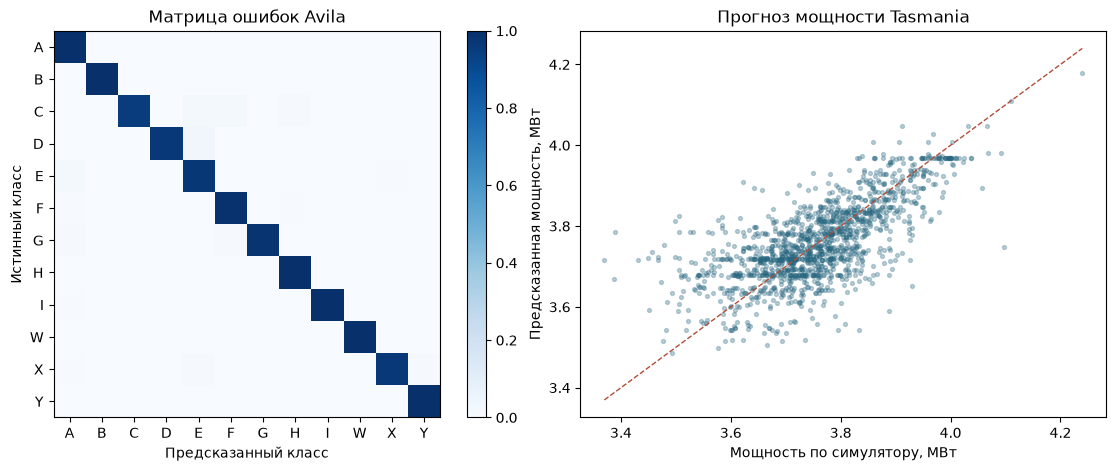

In [6]:
plot_predictions(tasks, results)

## Выводы

In [7]:
print(comparison_text(tasks, results, selections))
relative_path = save_scores(LAB, results)
print(f"Метрики сохранены в {relative_path.as_posix()}")

Avila (macro-F1)
По кросс-валидации выбран вариант «Только веса классов».
Среднее на фолдах: 0.9041 до настройки и 0.9215 после.
Sklearn на тесте: 0.9582 до настройки и 0.9852 после.
Своя модель на тесте: 0.9587 до настройки и 0.9747 после.
Разница со sklearn на тесте: +0.0005 до настройки и -0.0105 после.

Tasmania (MAE, МВт)
По кросс-валидации выбран вариант «Геометрия и ограничения дерева».
Среднее на фолдах: 0.0778 до настройки и 0.0634 после.
Sklearn на тесте: 0.0769 до настройки и 0.0616 после.
Своя модель на тесте: 0.0774 до настройки и 0.0616 после.
Разница со sklearn на тесте: +0.0005 до настройки и +0.0000 после.
Метрики сохранены в results/lab_03.csv
